<a href="https://colab.research.google.com/github/asema405/Maachine_Learning/blob/main/ML_PR5_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

sns.set_theme(style="whitegrid")
print("Китепканалар ийгиликтүү жүктөлдү!")

Китепканалар ийгиликтүү жүктөлдү!


In [5]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)

print("Датасеттин өлчөмү:", df.shape)
display(df.head())

Датасеттин өлчөмү: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [6]:
print("Мамычалар:")
print(df.columns.tolist())

print("\nМаалымат түрлөрү:")
df.info()

print("\nБош маанилер:")
print(df.isnull().sum())

print("\nСандык статистика:")
display(df.describe())

Мамычалар:
['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']

Маалымат түрлөрү:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB

Бош маанилер:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Сандык статистика:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


Класстардын саны:
high_tip
0    108
1    136
Name: count, dtype: int64

Класстардын үлүшү:
high_tip
0    0.443
1    0.557
Name: proportion, dtype: float64


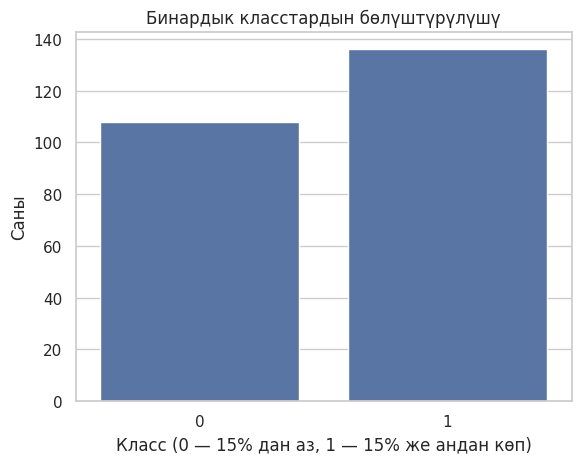

In [7]:

df["tip_rate"] = df["tip"] / df["total_bill"]

# 1 — чайпул эсептин 15% же андан көп
# 0 — чайпул эсептин 15% дан аз
df["high_tip"] = (df["tip_rate"] >= 0.15).astype(int)

print("Класстардын саны:")
print(df["high_tip"].value_counts().sort_index())

print("\nКласстардын үлүшү:")
print(df["high_tip"].value_counts(normalize=True).sort_index().round(3))

sns.countplot(data=df, x="high_tip")
plt.title("Бинардык класстардын бөлүштүрүлүшү")
plt.xlabel("Класс (0 — 15% дан аз, 1 — 15% же андан көп)")
plt.ylabel("Саны")
plt.show()

In [8]:
# Максаттуу белги
y = df["high_tip"]

# Модель колдоно турган белгилер
X = df[[
    "total_bill",
    "size",
    "sex",
    "smoker",
    "day",
    "time"
]]

numeric_features = ["total_bill", "size"]
categorical_features = ["sex", "smoker", "day", "time"]

print("X өлчөмү:", X.shape)
print("y өлчөмү:", y.shape)

NameError: name 'df' is not defined

X өлчөмү: (244, 6)
y өлчөмү: (244,)


In [9]:
# 60% — окутуу, 20% — validation, 20% — test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTrain класстары:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation класстары:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTest класстары:")
print(y_test.value_counts(normalize=True).round(3))

NameError: name 'train_test_split' is not defined

Train: (146, 6)
Validation: (49, 6)
Test: (49, 6)

Train класстары:
high_tip
1    0.555
0    0.445
Name: proportion, dtype: float64

Validation класстары:
high_tip
1    0.551
0    0.449
Name: proportion, dtype: float64

Test класстары:
high_tip
1    0.571
0    0.429
Name: proportion, dtype: float64


In [10]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

print("Logistic Regression модели окутулду!")

NameError: name 'Pipeline' is not defined

Logistic Regression модели окутулду!


In [11]:
# 1-класстын ыктымалдыгы
y_val_proba = model.predict_proba(X_val)[:, 1]
y_test_proba = model.predict_proba(X_test)[:, 1]

# Демейки босого — 0.5
y_test_default = (y_test_proba >= 0.5).astype(int)

print("Биринчи 10 ыктымалдык:")
print(np.round(y_test_proba[:10], 3))

print("\nБиринчи 10 класс божомолу:")
print(y_test_default[:10])

Биринчи 10 ыктымалдык:
[0.67  0.839 0.552 0.461 0.731 0.297 0.664 0.616 0.441 0.572]

Биринчи 10 класс божомолу:
[1 1 1 0 1 0 1 1 0 1]


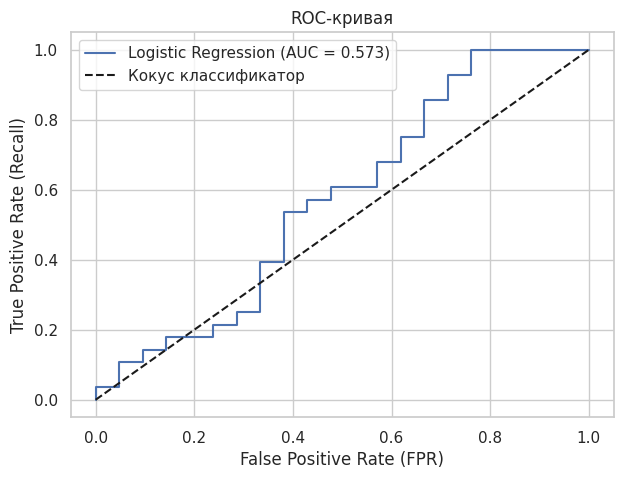

ROC-AUC: 0.573


In [12]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_test_proba)
roc_auc = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Кокус классификатор")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-кривая")
plt.legend()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")

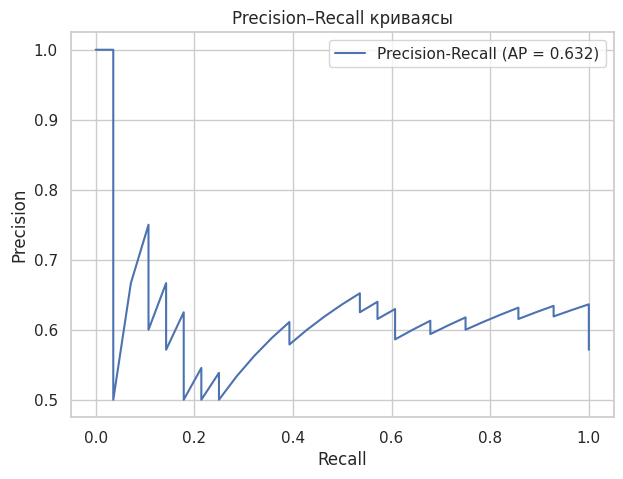

Average Precision (PR-AUC көрсөткүчү): 0.632


In [13]:
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test, y_test_proba
)

pr_auc = average_precision_score(y_test, y_test_proba)

plt.figure(figsize=(7, 5))
plt.plot(recall_values, precision_values,
         label=f"Precision-Recall (AP = {pr_auc:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall криваясы")
plt.legend()
plt.show()

print(f"Average Precision (PR-AUC көрсөткүчү): {pr_auc:.3f}")

In [14]:
# Мисал үчүн ката баалары.
# Агай берген маанилер болсо, ушул эки сапты алмаштыр.
C_FP = 1
C_FN = 3

thresholds_to_check = np.arange(0.05, 0.96, 0.01)

costs = []

for threshold in thresholds_to_check:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    ).ravel()

    total_cost = C_FP * fp + C_FN * fn
    costs.append(total_cost)

best_index = int(np.argmin(costs))
best_threshold = float(thresholds_to_check[best_index])

print(f"Тандалган босого: {best_threshold:.2f}")
print(f"Validation'деги минималдуу жалпы ката баасы: {costs[best_index]}")
print(f"0.5 босогосундагы баа: {costs[np.argmin(np.abs(thresholds_to_check - 0.5))]}")

Тандалган босого: 0.13
Validation'деги минималдуу жалпы ката баасы: 21
0.5 босогосундагы баа: 50


In [15]:
def evaluate_threshold(y_true, probabilities, threshold, name):
    y_pred = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Модель": name,
        "Босого": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Жалпы ката баасы": C_FP * fp + C_FN * fn
    }

results = pd.DataFrame([
    evaluate_threshold(y_test, y_test_proba, 0.5, "Демейки"),
    evaluate_threshold(y_test, y_test_proba, best_threshold, "Тандалган")
])

display(results.round(3))

,Модель,Босого,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Жалпы ката баасы
0,Демейки,0.50,0.612,0.622,0.821,0.708,7,14,5,23,29
1,Тандалган,0.13,0.571,0.571,1.000,0.727,0,21,0,28,21


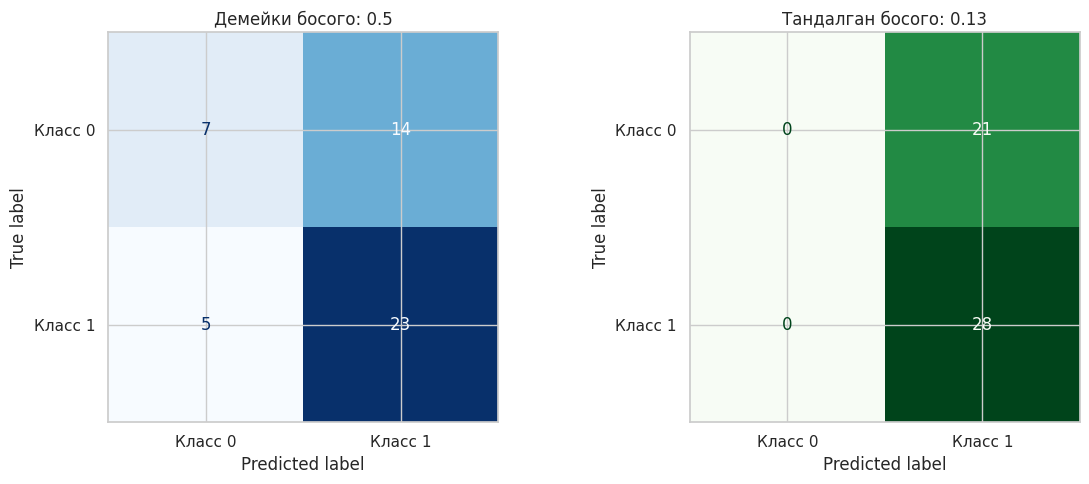

In [16]:
y_test_default = (y_test_proba >= 0.5).astype(int)
y_test_selected = (y_test_proba >= best_threshold).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_default,
    labels=[0, 1],
    display_labels=["Класс 0", "Класс 1"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Демейки босого: 0.5")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_selected,
    labels=[0, 1],
    display_labels=["Класс 0", "Класс 1"],
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title(f"Тандалган босого: {best_threshold:.2f}")

plt.tight_layout()
plt.show()

In [17]:
print("=== ДАТАСЕТ ===")
print("Жалпы саптар:", len(df))
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\n=== AUC ===")
print(f"ROC-AUC: {roc_auc:.3f}")
print(f"Average Precision: {pr_auc:.3f}")

print("\n=== БОСОГОЛОР ===")
print(f"Демейки босого: 0.50")
print(f"Тандалган босого: {best_threshold:.2f}")

print("\n=== МЕТРИКАЛАР ===")
display(results.round(3))

=== ДАТАСЕТ ===
Жалпы саптар: 244
Train: 146
Validation: 49
Test: 49

=== AUC ===
ROC-AUC: 0.573
Average Precision: 0.632

=== БОСОГОЛОР ===
Демейки босого: 0.50
Тандалган босого: 0.13

=== МЕТРИКАЛАР ===


,Модель,Босого,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Жалпы ката баасы
0,Демейки,0.50,0.612,0.622,0.821,0.708,7,14,5,23,29
1,Тандалган,0.13,0.571,0.571,1.000,0.727,0,21,0,28,21


# Практическая работа № 5. Классификатор и анализ метрик

## 1. Цель работы

Построить модель бинарной классификации, оценить её качество с помощью матрицы ошибок и метрик классификации, исследовать ROC-кривую и Precision–Recall кривую, а также подобрать порог с учётом стоимости ошибок.

## 2. Используемые данные

В работе использован датасет `tips.csv`, содержащий сведения о сумме счёта, чаевых, размере компании и других характеристиках посещения ресторана.

Для учебной задачи создан бинарный целевой признак `high_tip`:

- `1` — чаевые составляют 15% или более от суммы счёта;
- `0` — чаевые составляют менее 15% от суммы счёта.

Признаки `tip` и `tip_rate` не использовались в качестве входных данных модели, чтобы исключить утечку целевой информации.

## 3. Подготовка данных

Данные разделены на обучающую, валидационную и тестовую выборки в соотношении 60:20:20. Для сохранения пропорций классов применён параметр `stratify`.

Числовые признаки обработаны с помощью заполнения пропусков медианой и стандартизации. Категориальные признаки обработаны заполнением пропусков наиболее частым значением и кодированием One-Hot Encoding.

В качестве алгоритма классификации использована логистическая регрессия (`LogisticRegression`).

## 4. Оценка качества модели

Для оценки использованы Accuracy, Precision, Recall, F1, ROC-AUC и Average Precision.

Полученные значения:

- ROC-AUC: **[вставить результат]**.
- Average Precision: **[вставить результат]**.
- Accuracy при пороге 0,5: **[вставить результат]**.
- Precision при пороге 0,5: **[вставить результат]**.
- Recall при пороге 0,5: **[вставить результат]**.
- F1 при пороге 0,5: **[вставить результат]**.

ROC-AUC характеризует способность модели различать классы при различных порогах. Average Precision обобщает качество Precision–Recall кривой.

## 5. Выбор порога классификации

Для учебного примера приняты условные стоимости ошибок: FP = 1, FN = 3. Это означает, что ложноотрицательная ошибка считается в три раза дороже ложноположительной.

Порог подобран на валидационной выборке путём минимизации общей стоимости ошибок:

**Общая стоимость = 1 × FP + 3 × FN.**

Выбранный порог: **[вставить результат]**.

После выбора порога качество модели оценено на тестовой выборке. Тестовые данные не использовались для подбора порога.

## 6. Сравнение порогов

| Метрика | Порог 0,5 | Выбранный порог |
|---|---:|---:|
| Accuracy | [значение] | [значение] |
| Precision | [значение] | [значение] |
| Recall | [значение] | [значение] |
| F1 | [значение] | [значение] |
| Общая стоимость ошибок | [значение] | [значение] |

## 7. Интерпретация матрицы ошибок

- **TN** — модель правильно определила, что чаевые составляют менее 15% от суммы счёта.
- **FP** — модель ошибочно определила чаевые как 15% или более.
- **FN** — модель не обнаружила случай, когда чаевые составляли 15% или более.
- **TP** — модель правильно обнаружила чаевые в размере 15% или более.

## 8. Вывод

В ходе работы была построена модель бинарной классификации на основе логистической регрессии. Были построены матрица ошибок, ROC-кривая и Precision–Recall кривая, а также рассчитаны основные метрики классификации.

Сравнение порога 0,5 с порогом, выбранным на валидационной выборке, позволило оценить влияние порога на Precision, Recall, F1 и стоимость ошибок. При выборе итогового порога важно учитывать не только Accuracy, но и последствия ложноположительных и ложноотрицательных решений.

Стоимость ошибок в данной работе задана условно для учебного примера. При использовании реальной задачи её необходимо заменить стоимостью, определённой преподавателем или предметной областью.
